In [583]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

from bwLabel import labeling
from psColor import Gray2PseudoColor, CreateColorMap

%matplotlib inline

In [584]:
def show_image(img, title="Imagem", cmap=None):
    plt.figure(figsize=(8,6))
    if len(img.shape) == 3:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img_rgb)
    else:
        plt.imshow(img, cmap=cmap if cmap else 'gray')
    plt.title(title)
    plt.axis('off')
    plt.show()        

In [585]:
def preprocess_and_binarize(image_path, w_L=1.0, min_thr=10):
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Não foi possível carregar a imagem: {image_path}")

    blurred = cv2.GaussianBlur(img, (5, 5), 0)

    # Lab em float: L in [0, 100], a,b aproximadamente in [-127, 127]
    lab = cv2.cvtColor(blurred.astype(np.float32) / 255.0, cv2.COLOR_BGR2Lab)

    # Cor do fundo = mediana (assume que o fundo ocupa mais de metade da imagem)
    bg = np.median(lab.reshape(-1, 3), axis = 0)

    # Distância à cor do fundo; w_L baixo => sombras (variam sobretudo em L) ignoradas
    dL = lab[:, :, 0] - bg[0]
    da = lab[:, :, 1] - bg[1]
    db = lab[:, :, 2] - bg[2]
    dist = np.sqrt(w_L * dL**2 + da**2 + db**2)

    # Para uint8 e limiar automático com um mínimo para não segmentar ruído
    d8 = np.clip(dist * 2.55, 0, 255).astype(np.uint8)
    t, binary = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if t < min_thr * 2.55:
        _, binary = cv2.threshold(d8, min_thr * 2.55, 255, cv2.THRESH_BINARY)

    return img, binary

In [586]:
def apply_morphology(binary_img):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
    opened = cv2.morphologyEx(binary_img, cv2.MORPH_OPEN, kernel)
    cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

    # Preencher buracos internos
    contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(cleaned)
    cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)

    return filled

In [587]:
def split_touching(img, mask, frac=0.7):
    """Devolve (lista de contornos, máscara com as peças separadas)."""
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)

    # Raio típico = mediana do raio máximo de cada componente
    n, comp = cv2.connectedComponents(mask)
    radii = [dist[comp == i].max() for i in range(1, n)]
    if not radii:
        return [], mask
    r = np.median(radii)

    # Sementes seguras (centros das peças) e fundo seguro
    sure_fg = (dist > frac * r).astype(np.uint8) * 255
    sure_bg = cv2.dilate(mask, np.ones((3, 3), np.uint8), iterations=2)
    unknown = cv2.subtract(sure_bg, sure_fg)

    _, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1 # fundo passa a 1, peças a 2, 3, ...
    markers[unknown == 255] = 0 # zona a decidir pelo watershed

    markers = cv2.watershed(img, markers)

    contours = []
    for lbl in range(2, markers.max() + 1):
        piece = ((markers == lbl) & (mask > 0)).astype(np.uint8) * 255
        cnts, _ = cv2.findContours(piece, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if cnts:
            contours.append(max(cnts, key=cv2.contourArea))

    # Máscara com as fronteiras a preto (para o bwLabel mostrar peças separadas)
    separated = mask.copy()
    border = (markers == -1).astype(np.uint8)
    border = cv2.dilate(border, np.ones((3, 3), np.uint8))
    separated[border > 0] = 0

    return contours, separated    

In [588]:
"""
def extract_lego_feature(binary_img):
    contours, hierarchy = cv2.findContours(binary_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    features_list = []

    for cnt in contours:
        area = cv2.contourArea(cnt)

        if area < 300:
            continue

        rect = cv2.minAreaRect(cnt)
        (center_x, center_y), (width, height), angle = rect

        w = max(width, height)
        h = min(width, height)

        aspect_ratio = w / h if h > 0 else 0

        extent = area / (w * h) if w * h > 0 else 0

        hull = cv2.convexHull(cnt)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area > 0 else 0

        features_list.append({
            'contour': cnt,
            'area': area,
            'width': w,
            'height': h,
            'aspect_ratio': aspect_ratio,
            'extent': extent,
            'solidity': solidity,
            'rect': rect
        })
    return features_list   
"""

def extract_lego_features(contours):
    features_list = []
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 300:
            continue

        rect = cv2.minAreaRect(cnt)
        (cx, cy), (width, height), angle = rect
        w, h = max(width, height), min(width, height)

        aspect_ratio = w / h if h > 0 else 0
        extent = area / (w * h) if w * h > 0 else 0
        hull_area = cv2.contourArea(cv2.convexHull(cnt))
        solidity = area / hull_area if hull_area > 0 else 0

        features_list.append({
            'contour': cnt, 'area': area, 'width': w, 'height': h,
            'aspect_ratio': aspect_ratio, 'extent': extent,
            'solidity': solidity, 'rect': rect
        })
    return features_list    

In [589]:
def classify_lego(feature):
    area = feature['area']
    aspect_ratio = feature['aspect_ratio']
    extent = feature['extent']

    if extent < 0.90:
        return "Indef."

    if 0.8 <= aspect_ratio < 1.25:
        return "2x2"
    elif 1.75 <= aspect_ratio < 2.25:
        return "2x4"
    elif 2.75 <= aspect_ratio < 3.25:
        return "2x6"
    elif 3.6 <= aspect_ratio < 4.2:
        return "2x8"
    else:
        return "Indef."                

In [590]:
def touches_border(cnt, shape, margin=2):
    x, y, w, h = cv2.boundingRect(cnt)
    H, W = shape[:2]
    return x <= margin or y <= margin or (x + w) >= W - margin or (y + h) >= H - margin

def classify_by_length(feature, L={"2x2": 92, "2x4": 181, "2x6": 272, "2x8": 362}, tol=0.12):
    w = feature['width']
    for name, length in L.items():
        if abs(w - length) <= tol * length:
            return name
    return "Indef."        

In [591]:
def process_lego_image(image_path):
    orig_img, binary = preprocess_and_binarize(image_path)
    cleaned_binary = apply_morphology(binary)

    contours, separated = split_touching(orig_img, cleaned_binary)
    features = extract_lego_features(contours)

    #features = extract_lego_feature(cleaned_binary)

    counts = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0, "Indef.": 0}

    out_img = orig_img.copy()

    for feat in features:
        if touches_border(feat['contour'], orig_img.shape):
            label = classify_by_length(feat)
        else:
            label = classify_lego(feat)
        counts[label] += 1        

        box = cv2.boxPoints(feat['rect'])
        box = np.int32(box)
        cv2.drawContours(out_img, [box], 0, (0, 255, 0), 2)

        M = cv2.moments(feat['contour'])
        if M["m00"] != 0:
            cX = int(M["m10"] / M["m00"])
            cY = int(M["m01"] / M["m00"])
        else:
            cX, cY = int(feat['rect'][0][0]), int(feat['rect'][0][1])
        cv2.putText(out_img, label, (cX - 20, cY),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

        print(f"{label}: width={feat['width']:.0f} height={feat['height']:.0f} AR={feat['aspect_ratio']:.2f} extent={feat['extent']:.3f} solidity={feat['solidity']:.3f}")            

    print("--- CONTAGEM DE PEÇAS ---")
    for k, v in counts.items():
        if k!= "Indef.":
            print(f"Pecas {k}: {v}")
    if counts["Indef."] > 0:
        print(f"Outras / Indefinidas: {counts['Indef.']}")

    y = 20
    for k in ["2x2", "2x4", "2x6", "2x8"]:
        cv2.putText(out_img, f"Pecas {k}: {counts[k]}", (10, y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
        y += 22            
    
    show_image(cleaned_binary, "Imagem Processada (Binária)")
    show_image(out_img, "Deteção e Classificação Final")

    num_labels, labeled_img = labeling(cleaned_binary)
    cmap = CreateColorMap(num_labels, firstColorBlack=1)
    pseudo_color_img = Gray2PseudoColor(labeled_img.astype(np.uint8), cmap)       
    show_image(pseudo_color_img, "Etiquetação em Falsa Cor (bwLabel + psColor)")                             

2x6: width=272 height=92 AR=2.96 extent=0.972 solidity=0.981
2x4: width=181 height=45 AR=4.02 extent=0.987 solidity=0.994
Indef.: width=142 height=86 AR=1.66 extent=0.695 solidity=0.771
2x2: width=92 height=92 AR=1.00 extent=0.963 solidity=0.976
2x4: width=181 height=90 AR=2.02 extent=0.974 solidity=0.983
--- CONTAGEM DE PEÇAS ---
Pecas 2x2: 1
Pecas 2x4: 2
Pecas 2x6: 1
Pecas 2x8: 0
Outras / Indefinidas: 1


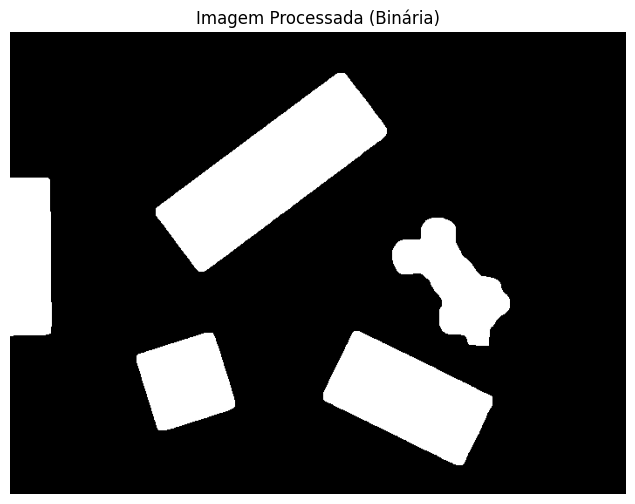

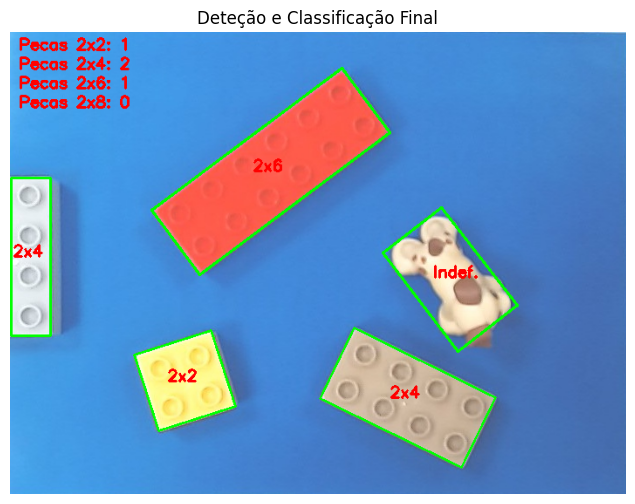

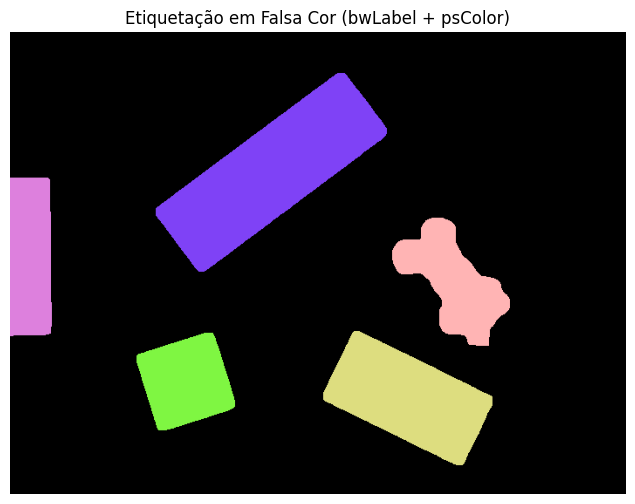

In [592]:
process_lego_image(image_path="imagens/lego32.jpg")